# Early results 2 - my bulk checkpoint

I freeze a separate snapshot when bulk collection pauses. I use **only the newly collected training answers** from my 1,000-puzzle study. I do not mix in the earlier 60-puzzle pilot, fit from held-out outcomes, or estimate missing-model results.

My provisional regression uses the same rating and multiple-move predictors as the final plan. My descriptive tree retains depth 2, minimum leaf 40 and the same three predictors. I apply the minimum-data rules in `experiments/bulk_v1/interim_plan.json`; an unavailable model receives an explicit empty panel. I make no final hypothesis-test, model-ranking or held-out prediction claim.

I freeze this checkpoint's training CSVs and code hash on the first run. Later collection cannot change `early_results_2`. I use a new numbered checkpoint for a later snapshot. The original pilot is notebook 03, collection is 04 and final analysis is 06.

## 1. I freeze the audited training-only snapshot

In [1]:

from pathlib import Path
from datetime import datetime, timezone
import json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning, PerfectSeparationError
import joblib, nbformat
from IPython.display import display

ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'experiments/stage_index.json').exists())
BASE=ROOT/'data/experiments/bulk_v1'
OUT=ROOT/'data/analysis/early_results_2';OUT.mkdir(exist_ok=True)
FIG=ROOT/'figures/early_results_2';FIG.mkdir(exist_ok=True)
CFG=ROOT/'experiments/bulk_v1'
CONFIG=json.loads((CFG/'config.json').read_text())
PLAN=json.loads((CFG/'interim_plan.json').read_text())
def sha(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def save(path,value):Path(path).write_text(json.dumps(value,indent=2)+'\n',encoding='utf-8')
book=nbformat.read(ROOT/'notebooks/05_early_results_2.ipynb',as_version=4)
code_sha=hashlib.sha256('\n\n'.join(c.source for c in book.cells if c.cell_type=='code').encode()).hexdigest()

# I freeze this checkpoint once. Later collection cannot overwrite its input subset.
if not (OUT/'snapshot.json').exists():
    metadata={}
    for name,spec in CONFIG['models'].items():
        folder=BASE/name;path=folder/'results.csv'
        audit=json.loads((folder/'audit.json').read_text())
        assert audit['passed'] and audit['results_sha256']==sha(path), 'Pause collection before freezing this checkpoint.'
        assert audit['sample_sha256']==sha(BASE/'puzzles.csv')
        assert audit['manifest_sha256']==sha(BASE/'manifest.json')
        frame=pd.read_csv(path,dtype={'puzzle_id':str})
        assert len(frame)==1000 and frame.puzzle_id.nunique()==1000
        train=frame.loc[frame.status.eq('completed')&frame.split.eq('train')].copy()
        assert train.split.eq('train').all()
        destination=OUT/name;destination.mkdir(exist_ok=True)
        train.to_csv(destination/'training_results.csv',index=False)
        save(destination/'source_audit.json',audit)
        summary=json.loads((folder/'summary.json').read_text())
        pause=json.loads((folder/'pause.json').read_text()) if (folder/'pause.json').exists() else None
        metadata[name]={'label':spec['label'],'training_n':len(train),'completed_research_n':int(frame.status.eq('completed').sum()),
                        'completed_test_n':int((frame.status.eq('completed')&frame.split.eq('test')).sum()),
                        'training_sha256':sha(destination/'training_results.csv'),'source_results_sha256':sha(path),
                        'status':summary['status'],'pause':pause}
        assert audit['results_sha256']==sha(path), 'The live result changed while freezing; retry after collection pauses.'
    snapshot={'name':'early_results_2','created_utc':datetime.now(timezone.utc).isoformat(),
              'sample_sha256':sha(BASE/'puzzles.csv'),'manifest_sha256':sha(BASE/'manifest.json'),
              'interim_plan_sha256':sha(CFG/'interim_plan.json'),'analysis_code_sha256':code_sha,'models':metadata,
              'scope':'Frozen training-only exploratory checkpoint; no pooled pilot data, held-out evaluation or final hypothesis tests.'}
    save(OUT/'snapshot.json',snapshot)
else:snapshot=json.loads((OUT/'snapshot.json').read_text())
assert snapshot['analysis_code_sha256']==code_sha and snapshot['interim_plan_sha256']==sha(CFG/'interim_plan.json')
models={};rows=[]
for name,meta in snapshot['models'].items():
    path=OUT/name/'training_results.csv';assert sha(path)==meta['training_sha256']
    data=pd.read_csv(path,dtype={'puzzle_id':str})
    assert len(data)==meta['training_n'] and data.split.eq('train').all()
    correct=int(data.success.sum()) if len(data) else 0
    models[name]={'label':meta['label'],'data':data,'n':len(data),'correct':correct,
                  'accuracy':correct/len(data) if len(data) else None,'fit':None,'tree':None}
    rows.append({'Model':meta['label'],'Training answers':len(data),'Correct':correct,
                 'Accuracy':f'{correct/len(data):.1%}' if len(data) else 'No new answers','Collection status':meta['status']})
display(pd.DataFrame(rows))
print('I use only the frozen bulk training subset. This checkpoint does not change as collection resumes.')


,Model,Training answers,Correct,Accuracy,Collection status
0,GPT-OSS 120B,0,0,No new answers,paused_for_quota
1,Gemini 3.5 Flash-Lite,404,174,43.1%,paused_for_quota


I use only the frozen bulk training subset. This checkpoint does not change as collection resumes.


## 2. I fit provisional models only where the data support them

In [2]:
def fit_tree(frame,target,max_depth=2,min_leaf=10):
    values=frame.to_numpy(dtype=float);labels=np.asarray(target,dtype=int)
    assert len(values)==len(labels) and len(labels)>0 and np.isin(labels,[0,1]).all()
    assert np.isfinite(values).all()
    names=list(frame.columns)
    def grow(indices,depth):
        n=len(indices);positive=int(labels[indices].sum());p=positive/n
        node={'n':n,'correct':positive,'probability':p,'gini':2*p*(1-p),'predicted_class':int(p>=.5)}
        if depth>=max_depth or n<2*min_leaf or positive in [0,n]:return node
        best_gain=0.;best=None
        for j,name in enumerate(names):
            unique=np.unique(values[indices,j])
            for threshold in (unique[:-1]+unique[1:])/2:
                left=indices[values[indices,j]<=threshold];right=indices[values[indices,j]>threshold]
                if min(len(left),len(right))<min_leaf:continue
                lp=float(labels[left].mean());rp=float(labels[right].mean())
                gain=node['gini']-(len(left)*2*lp*(1-lp)+len(right)*2*rp*(1-rp))/n
                if gain>best_gain+1e-12:best_gain=gain;best=(name,float(threshold),left,right)
        if best is not None:
            name,threshold,left,right=best
            node.update(feature=name,threshold=threshold,gini_gain=best_gain,left=grow(left,depth+1),right=grow(right,depth+1))
        return node
    return grow(np.arange(len(labels)),0)



status={}
for name,item in models.items():
    data=item['data'];n=item['n'];positive=item['correct'];negative=n-positive;folder=OUT/name
    reasons=[]
    if n>=60 and min(positive,negative)>=15:
        X=pd.DataFrame({'const':np.ones(n),'rating_500':(data.puzzle_rating-1500)/500,
                        'multi_move':data.total_solver_moves.gt(1).astype(int)})
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('error',PerfectSeparationWarning)
                fit=sm.GLM(data.success.astype(int),X,family=sm.families.Binomial()).fit()
            assert fit.converged and np.isfinite(fit.params).all() and np.isfinite(fit.bse).all()
            ci=fit.conf_int()
            coefficients=pd.DataFrame({'term':fit.params.index,'coefficient':fit.params.values,
                         'odds_ratio':np.exp(fit.params.values),'or_ci_low':np.exp(ci[0].values),'or_ci_high':np.exp(ci[1].values)})
            assert np.isfinite(coefficients.select_dtypes('number').to_numpy()).all()
            coefficients.to_csv(folder/'logistic_coefficients.csv',index=False)
            joblib.dump(fit,folder/'logistic_regression.joblib');item['fit']=fit
        except (PerfectSeparationWarning,PerfectSeparationError,ValueError,AssertionError,np.linalg.LinAlgError):
            reasons.append('Regression convergence/separation check did not pass.')
    else:reasons.append('Regression needs 60 training answers and at least 15 successes and 15 failures.')
    if n>=80 and min(positive,negative)>=15:
        tree=fit_tree(data[['puzzle_rating','total_solver_moves','legal_moves']],data.success.astype(int),max_depth=2,min_leaf=40)
        save(folder/'decision_tree.json',{'tree':tree,'features':['puzzle_rating','total_solver_moves','legal_moves'],
             'training_ids':sorted(data.puzzle_id),'scope':'Interim descriptive training-only fit; no held-out performance claim.'})
        item['tree']=tree
    else:reasons.append('Tree needs 80 training answers and at least 15 successes and 15 failures.')
    status[name]={'n':n,'correct':positive,'accuracy':item['accuracy'],'regression_fitted':item['fit'] is not None,
                  'tree_fitted':item['tree'] is not None,'reasons':reasons}
    save(folder/'status.json',status[name])
pd.DataFrame(rows).to_csv(OUT/'results_summary.csv',index=False)
save(OUT/'summary.json',{'models':status,'snapshot_sha256':sha(OUT/'snapshot.json'),
     'scope':'Exploratory training-only interim results. I leave the final sample, predictors, settings and 200-case holdout unchanged.'})


## 3. I review three clearly labeled graphs

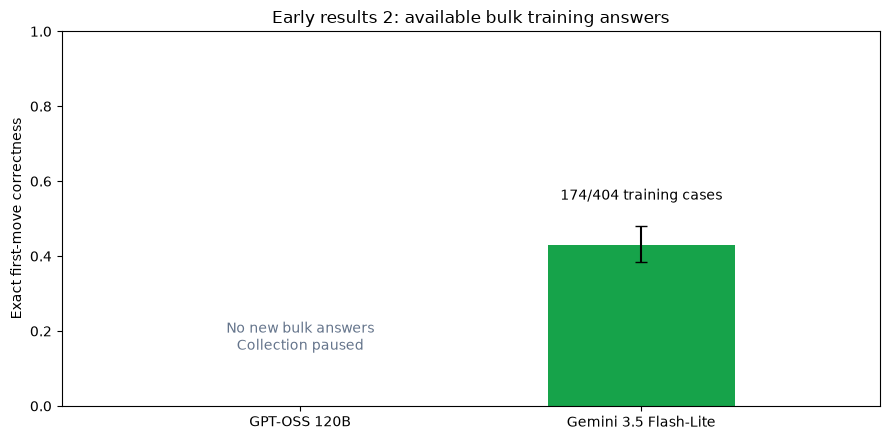

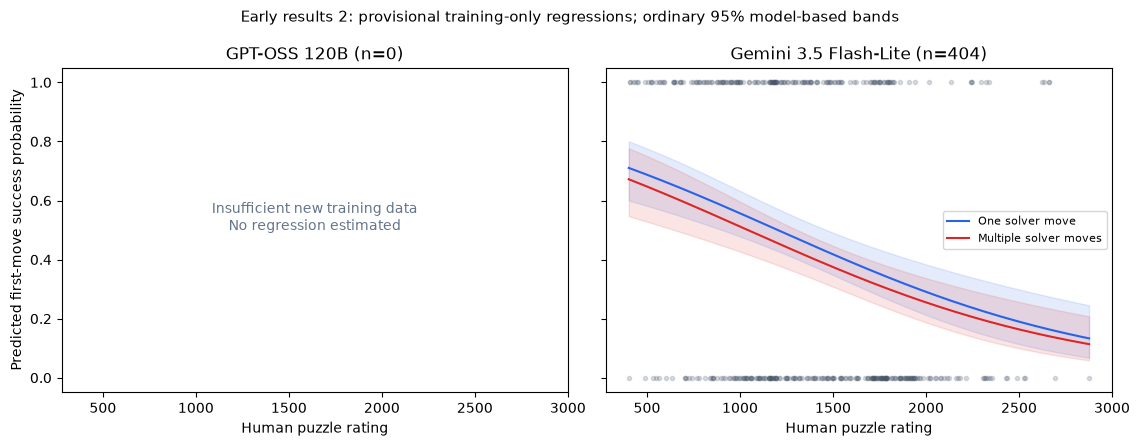

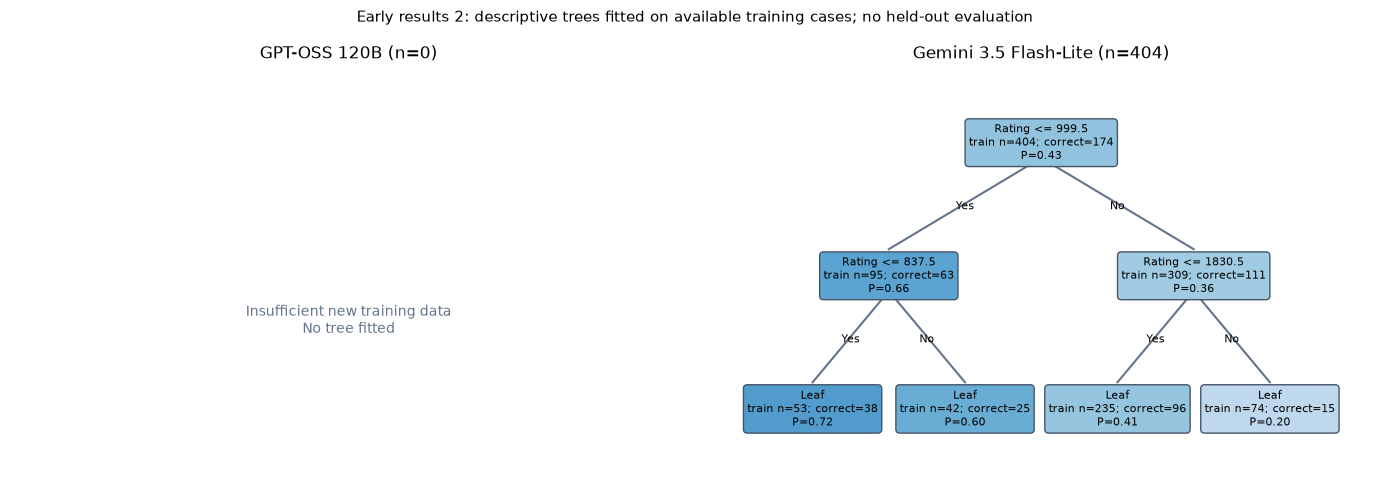

I saved three figures in figures/early_results_2/. The frozen final analysis remains notebook 06.


In [3]:

def wilson(correct,n):
    p=correct/n;z=1.96;center=(p+z*z/(2*n))/(1+z*z/n)
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
    return center-half,center+half

fig,ax=plt.subplots(figsize=(9,4.5))
for i,item in enumerate(models.values()):
    if item['n']:
        p=item['accuracy'];low,high=wilson(item['correct'],item['n'])
        ax.bar(i,p,color=['#2563eb','#16a34a'][i],width=.55)
        ax.errorbar(i,p,yerr=[[p-low],[high-p]],fmt='none',color='black',capsize=4)
        ax.text(i,p+.12,f"{item['correct']}/{item['n']} training cases",ha='center')
    else:ax.text(i,.15,'No new bulk answers\nCollection paused',ha='center',color='#64748b')
ax.set(xticks=[0,1],xticklabels=[m['label'] for m in models.values()],ylim=(0,1),xlim=(-.7,1.7),
       ylabel='Exact first-move correctness',title='Early results 2: available bulk training answers')
fig.tight_layout();fig.savefig(FIG/'accuracy.png',dpi=180);plt.show()

fig,axes=plt.subplots(1,2,figsize=(11.5,4.5),sharex=True,sharey=True)
for ax,item in zip(axes,models.values()):
    ax.set(title=f"{item['label']} (n={item['n']})",xlabel='Human puzzle rating',ylim=(-.05,1.05))
    if item['fit'] is None:
        ax.text(.5,.5,'Insufficient new training data\nNo regression estimated',ha='center',transform=ax.transAxes,color='#64748b');continue
    data=item['data'];rating=np.linspace(data.puzzle_rating.min(),data.puzzle_rating.max(),200)
    for group,color,label in [(0,'#2563eb','One solver move'),(1,'#dc2626','Multiple solver moves')]:
        grid=pd.DataFrame({'const':np.ones(200),'rating_500':(rating-1500)/500,'multi_move':np.full(200,group)})
        pred=item['fit'].get_prediction(grid).summary_frame();ax.plot(rating,pred['mean'],color=color,label=label)
        ax.fill_between(rating,pred['mean_ci_lower'],pred['mean_ci_upper'],color=color,alpha=.12)
    ax.scatter(data.puzzle_rating,data.success,s=9,alpha=.2,color='#475569');ax.legend(fontsize=8)
axes[0].set_ylabel('Predicted first-move success probability')
fig.suptitle('Early results 2: provisional training-only regressions; ordinary 95% model-based bands',fontsize=11)
fig.tight_layout();fig.savefig(FIG/'logistic_regression.png',dpi=180);plt.show()

feature_labels={'puzzle_rating':'Rating','total_solver_moves':'Solver moves','legal_moves':'Legal moves'}
def draw(ax,node,x=.5,width=.45,depth=0,parent=None,branch=None):
    y=1-depth*.35
    if parent:
        ax.plot([parent[0],x],[parent[1]-.04,y+.07],color='#64748b',zorder=0)
        ax.text((parent[0]+x)/2,(parent[1]+y)/2,branch,ha='center',fontsize=8)
    title=f"{feature_labels[node['feature']]} <= {node['threshold']:.1f}" if 'feature' in node else 'Leaf'
    ax.text(x,y,title+f"\ntrain n={node['n']}; correct={node['correct']}\nP={node['probability']:.2f}",ha='center',va='center',fontsize=8,
       bbox={'boxstyle':'round,pad=.35','facecolor':plt.cm.Blues(.15+.6*node['probability']),'edgecolor':'#475569'})
    if 'feature' in node:
        draw(ax,node['left'],x-width/2,width/2,depth+1,(x,y),'Yes');draw(ax,node['right'],x+width/2,width/2,depth+1,(x,y),'No')
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,item in zip(axes,models.values()):
    ax.set_axis_off();ax.set(xlim=(0,1),ylim=(.1,1.2),title=f"{item['label']} (n={item['n']})")
    if item['tree'] is None:ax.text(.5,.5,'Insufficient new training data\nNo tree fitted',ha='center',color='#64748b');continue
    draw(ax,item['tree'])
fig.suptitle('Early results 2: descriptive trees fitted on available training cases; no held-out evaluation',fontsize=11)
fig.tight_layout();fig.savefig(FIG/'decision_trees.png',dpi=180);plt.show()
print('I saved three figures in figures/early_results_2/. The frozen final analysis remains notebook 06.')


## My interpretation of this checkpoint

I collected **404 Gemini training answers, with 174 correct first moves (43.1%)**. The estimated rating odds ratio is **0.57 per 500 points** (ordinary 95% interval **0.46-0.71**), adjusting for multiple solver moves. I observe lower success as rating rises. The multiple-move odds ratio is 0.84 (0.55-1.26), so this checkpoint does not clearly separate that association from no association.

My depth-2 tree chose rating for every split, despite having solver-move count and legal-move count available. Its highest-rating leaf contains 15 correct answers out of 74 (20.3%); its lowest-rating leaf contains 38 out of 53 (71.7%). These training leaf rates do not measure held-out prediction accuracy or establish that other characteristics never matter.

I have no new GPT-OSS answers because its local usage guard paused generation. I have not fitted a new GPT-OSS regression or tree. My 200 held-out test puzzles remain unused for both models, and I keep the fixed final analysis plan unchanged. I resume collection in notebook 04; later answers cannot alter this frozen checkpoint.